# Aegean Brew Co. — Customer & Sales Analysis
**Tools:** SQL (SQLite) · Python (pandas, matplotlib)

**Business question:** An online specialty-coffee retailer has grown fast since launching in January 2024 and wants to know what's working. Which products make money? Do customers come back? Which acquisition channels bring valuable customers?

**Approach:**
1. Audit and clean four raw tables (customers, products, orders, order items), logging every data-quality issue and decision.
2. Build one analysis-ready table of order lines with revenue and margin.
3. Analyse trends, product profitability, cohort retention, acquisition channels, RFM segments and cancellations.
4. Turn the findings into recommendations for a non-technical founder.

*The dataset is synthetic but deliberately messy (duplicates, mixed date formats, inconsistent categories, test orders).*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
DATA = "../data/"

customers   = pd.read_csv(DATA + "customers.csv")
products    = pd.read_csv(DATA + "products.csv")
orders      = pd.read_csv(DATA + "orders.csv")
order_items = pd.read_csv(DATA + "order_items.csv")
for name, df in [("customers", customers), ("products", products), ("orders", orders), ("order_items", order_items)]:
    print(f"{name:12s} {df.shape}")

customers    (2525, 5)
products     (20, 5)
orders       (9974, 5)
order_items  (20069, 6)


## 1. Data cleaning
### Customers

In [2]:
print("duplicate rows:", customers.duplicated().sum())
print("duplicate ids:", customers.customer_id.duplicated().sum())
print(customers.country.value_counts().to_string())

duplicate rows: 25
duplicate ids: 25
country
Greece           1012
Germany           372
Italy             285
France            203
Cyprus            161
Spain             149
Netherlands       133
Austria           106
 Greece            23
GREECE             19
GR                 16
Deutschland         8
 Germany            6
FRANCE              6
GERMANY             5
ITALY               4
 France             3
AUSTRIA             3
SPAIN               2
 Netherlands        2
 Austria            2
 Italy              2
CYPRUS              1
 Cyprus             1
 Spain              1


In [3]:
cust = customers.drop_duplicates().copy()
assert cust.customer_id.is_unique

country_map = {"GR": "Greece", "DEUTSCHLAND": "Germany"}
c = cust.country.str.strip().str.upper()
cust["country"] = c.replace(country_map).str.title()
cust["country"] = cust.country.replace({"Gr": "Greece", "Deutschland": "Germany"})
print(cust.country.value_counts().to_string())

cust["signup_date"] = pd.to_datetime(cust.signup_date)
print("\nbirth_year missing:", cust.birth_year.isna().sum(), "| implausible (<1920):", (cust.birth_year < 1920).sum())
cust.loc[cust.birth_year < 1920, "birth_year"] = np.nan          # treat as unknown
print("acquisition_channel missing:", cust.acquisition_channel.isna().sum())
cust["acquisition_channel"] = cust.acquisition_channel.fillna("Unknown")

country
Greece         1059
Germany         387
Italy           287
France          210
Cyprus          162
Spain           151
Netherlands     134
Austria         110

birth_year missing: 180 | implausible (<1920): 6
acquisition_channel missing: 60


### Orders
`pd.to_datetime` on the raw column silently guesses formats. Rows like `05/03/2025 14:22` are **day-first** (European) — check one against an ISO row from the same customer if unsure. Parse each format explicitly.

In [4]:
iso = pd.to_datetime(orders.order_ts, format="%Y-%m-%d %H:%M:%S", errors="coerce")
dmy = pd.to_datetime(orders.order_ts, format="%d/%m/%Y %H:%M", errors="coerce")
print("ISO:", iso.notna().sum(), "| DD/MM/YYYY:", dmy.notna().sum(), "| unparsed:", (iso.isna() & dmy.isna()).sum())

ords = orders.copy()
ords["order_ts"] = iso.fillna(dmy)
ords["order_date"] = ords.order_ts.dt.normalize()

orphans = ~ords.customer_id.isin(cust.customer_id)
print("\norders without a real customer:")
print(ords[orphans])

ISO: 9674 | DD/MM/YYYY: 300 | unparsed: 0

orders without a real customer:
      order_id  customer_id            order_ts     status payment_method  \
9971     99001            0 2025-06-02 10:00:00  Delivered           Card   
9972     99002            0 2025-06-02 10:05:00  Delivered           Card   
9973     99003            0 2025-09-15 14:30:00  Delivered           Card   

     order_date  
9971 2025-06-02  
9972 2025-06-02  
9973 2025-09-15  


In [5]:
ords = ords[~orphans]                      # internal test orders (customer_id 0)
print("clean orders:", len(ords))

clean orders: 9971


### Order items

In [6]:
print("exact duplicate rows:", order_items.duplicated().sum())
print("quantity <= 0:", (order_items.quantity <= 0).sum())
items = order_items.drop_duplicates()
items = items[items.quantity > 0]
items = items[items.order_id.isin(ords.order_id)]   # drops test-order lines
assert items.item_id.is_unique
print("clean items:", len(items))

exact duplicate rows: 89
quantity <= 0: 25
clean items: 19952


### Data-quality log
| # | Issue | Rows affected | How found | Decision |
|---|---|---|---|---|
| 1 | Exact duplicate customer rows | 25 | `duplicated()` | Dropped |
| 2 | Inconsistent country values (case, whitespace, `GR`, `Deutschland`) | ~120 | `value_counts()` | Standardised to 8 English names |
| 3 | Missing birth_year | ~180 | `isna()` | Left as NaN; age analysis is optional |
| 4 | Birth year 1900 | 6 | `describe()` | Set to NaN (placeholder value) |
| 5 | Missing acquisition_channel | ~60 | `isna()` | Labelled "Unknown"; reported separately |
| 6 | Mixed timestamp formats (ISO + DD/MM/YYYY) | 300 | parse attempts | Parsed each format explicitly |
| 7 | Test orders from customer_id 0 (bulk kettle/grinder orders) | 3 orders | anti-join to customers | Excluded |
| 8 | Duplicate order_items rows (double ingest) | ~90 | `duplicated()`, `item_id` not unique | Dropped — would inflate revenue by ~€2.5k |
| 9 | Quantity 0 or −1 | ~25 | `describe()` | Dropped; returns are tracked via order status instead |
| 10 | `products.unit_price` ≠ price charged | — | comparing to `order_items.unit_price` | Always use the charged price for revenue |

### Analysis-ready table

In [7]:
order_lines = (items
    .merge(ords[["order_id", "customer_id", "order_date", "status", "payment_method"]], on="order_id", validate="many_to_one")
    .merge(cust[["customer_id", "signup_date", "country", "acquisition_channel"]], on="customer_id", validate="many_to_one")
    .merge(products[["product_id", "category", "product_name", "unit_cost"]], on="product_id", validate="many_to_one"))

order_lines["revenue"] = order_lines.quantity * order_lines.unit_price * (1 - order_lines.discount)
order_lines["cost"]    = order_lines.quantity * order_lines.unit_cost
order_lines["margin"]  = order_lines.revenue - order_lines.cost
order_lines["month"]   = order_lines.order_date.dt.to_period("M")
delivered = order_lines[order_lines.status == "Delivered"]
print(order_lines.shape, "| delivered net revenue: €{:,.0f}".format(delivered.revenue.sum()))

(19952, 20) | delivered net revenue: €440,204


## 2. Analysis
### 3.1 Trends

              revenue  orders  customers    aov
order_date                                     
2024        121576.88    2332        870  52.13
2025        318627.44    5918       1896  53.84

YoY revenue growth: 162%
Nov+Dec share of 2025 revenue: 28%


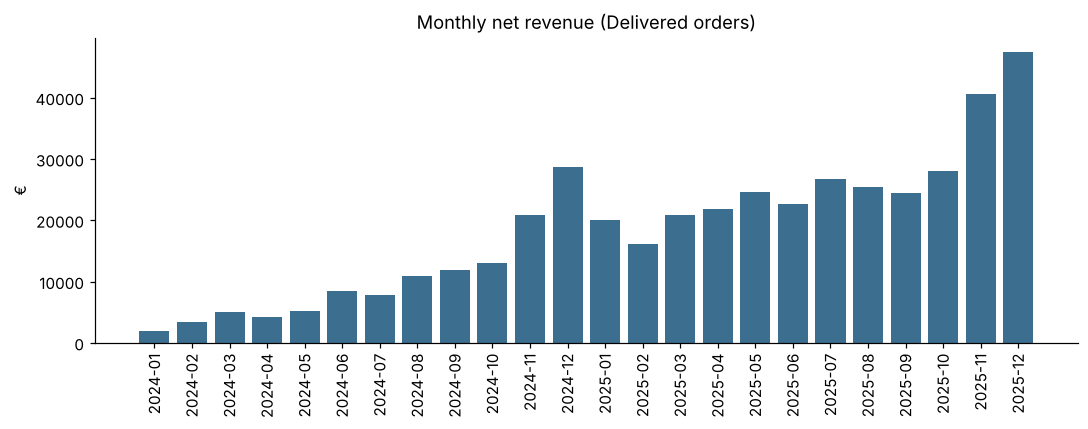

In [8]:
monthly = delivered.groupby("month").agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"))
monthly["aov"] = monthly.revenue / monthly.orders

fig, ax = plt.subplots()
ax.bar(monthly.index.astype(str), monthly.revenue, color="#3b6e8f")
ax.set_title("Monthly net revenue (Delivered orders)"); ax.set_ylabel("€")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

yearly = delivered.groupby(delivered.order_date.dt.year).agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"),
                                                               customers=("customer_id", "nunique"))
yearly["aov"] = yearly.revenue / yearly.orders
print(yearly.round(2))
print("\nYoY revenue growth: {:.0%}".format(yearly.revenue.iloc[1] / yearly.revenue.iloc[0] - 1))
print("Nov+Dec share of 2025 revenue: {:.0%}".format(
    monthly.loc["2025-11":"2025-12", "revenue"].sum() / monthly.loc["2025-01":"2025-12", "revenue"].sum()))

**Takeaway:** Revenue grew ~160% year on year, driven by more customers (870 → ~1,900) rather than bigger baskets (AOV is flat at ~€52–54). November–December is a pronounced peak (~28% of 2025 revenue), so stock and marketing should be planned around it.

### 3.2 Products

In [9]:
prod_perf = delivered.groupby(["category", "product_name"]).agg(
    units=("quantity", "sum"), revenue=("revenue", "sum"), margin=("margin", "sum")).reset_index()
prod_perf["margin_pct"] = prod_perf.margin / prod_perf.revenue
print(prod_perf.sort_values("revenue", ascending=False).round(2).to_string(index=False))

cat = delivered.groupby("category")[["revenue", "margin"]].sum()
cat["margin_pct"] = cat.margin / cat.revenue
print("\n", cat.sort_values("revenue", ascending=False).round(2))

    category              product_name  units  revenue   margin  margin_pct
Coffee Beans House Espresso Blend 500g   2597 43154.09 24975.09        0.58
   Equipment Electric Gooseneck Kettle    599 42802.20 20040.20        0.47
Coffee Beans         Brazil Santos 1kg   1294 39331.97 21215.97        0.54
   Equipment            Manual Grinder    824 36705.90 19401.90        0.53
   Equipment            Moka Pot 6-cup   1163 30731.30 17356.80        0.56
Coffee Beans Ethiopia Yirgacheffe 250g   2361 28089.92 16048.82        0.57
   Equipment           French Press 1L    792 25068.75 13980.75        0.56
   Equipment         Pour-over Dripper   1162 23028.50 13732.50        0.60
Coffee Beans             Kenya AA 250g   1640 22598.66 12266.66        0.54
Coffee Beans       Colombia Huila 250g   2037 21344.84 12382.04        0.58
   Equipment             Digital Scale    852 19272.50 11178.50        0.58
 Accessories            Travel Tumbler   1088 18638.05 10478.05        0.56
 Accessories

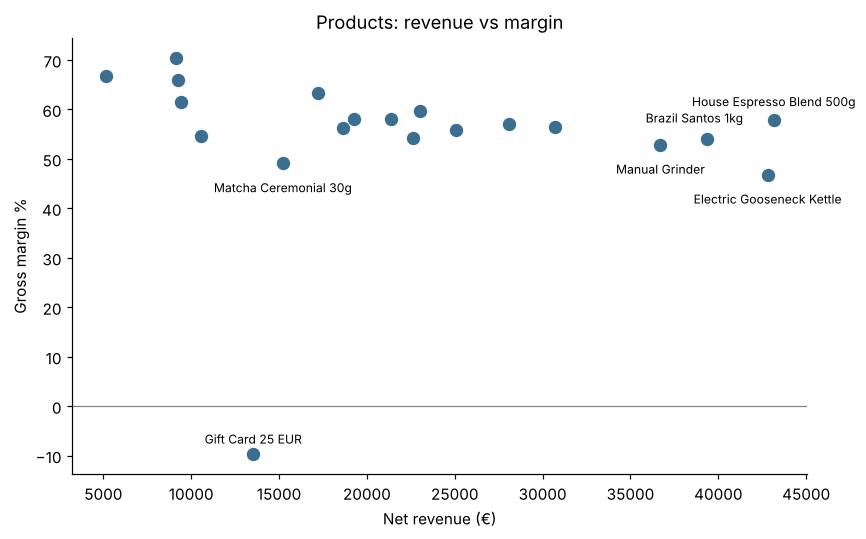

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(prod_perf.revenue, prod_perf.margin_pct * 100, s=60, color="#3b6e8f")
# label only the products worth talking about (offsets placed by hand to avoid overlaps)
labels = {"House Espresso Blend 500g": (0, 12), "Electric Gooseneck Kettle": (0, -16), "Brazil Santos 1kg": (-8, 14),
          "Manual Grinder": (0, -16), "Matcha Ceremonial 30g": (0, -16), "Gift Card 25 EUR": (0, 10)}
for r in prod_perf[prod_perf.product_name.isin(labels)].itertuples():
    ax.annotate(r.product_name, (r.revenue, r.margin_pct * 100), fontsize=8, xytext=labels[r.product_name],
                textcoords="offset points", ha="center", va="center")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Net revenue (€)"); ax.set_ylabel("Gross margin %"); ax.set_title("Products: revenue vs margin")
plt.tight_layout(); plt.show()

In [11]:
# Price changes over time: charged price by month for coffee beans
beans = delivered[delivered.category == "Coffee Beans"]
print(beans.groupby(["product_name", beans.order_date.dt.year]).unit_price.median().unstack())

order_date                 2024   2025
product_name                          
Brazil Santos 1kg          32.0  34.56
Colombia Huila 250g        11.0  11.88
Decaf Swiss Water 250g     13.0  14.04
Ethiopia Yirgacheffe 250g  12.5  13.50
House Espresso Blend 500g  17.5  18.90
Kenya AA 250g              14.5  15.66


**Takeaway:** Equipment and beans bring in similar revenue, but beans do it through repeat purchases at a steady ~56% margin. The gooseneck kettle is the #2 product by revenue but has the lowest margin of any physical product (~47%). **Gift cards lose money:** they're sold at face value cost, so every promo discount on them is a straight loss. Exclude them from discounts. Bean prices went up 8% in March 2025, and volumes don't appear to have suffered.

### 3.3 Retention cohorts

Customers with ≥1 delivered order: 2182
…of whom repeat (≥2): 61%
Signed up but never had a delivered order: 13%

Average month-1 to month-6 retention: 18.4%


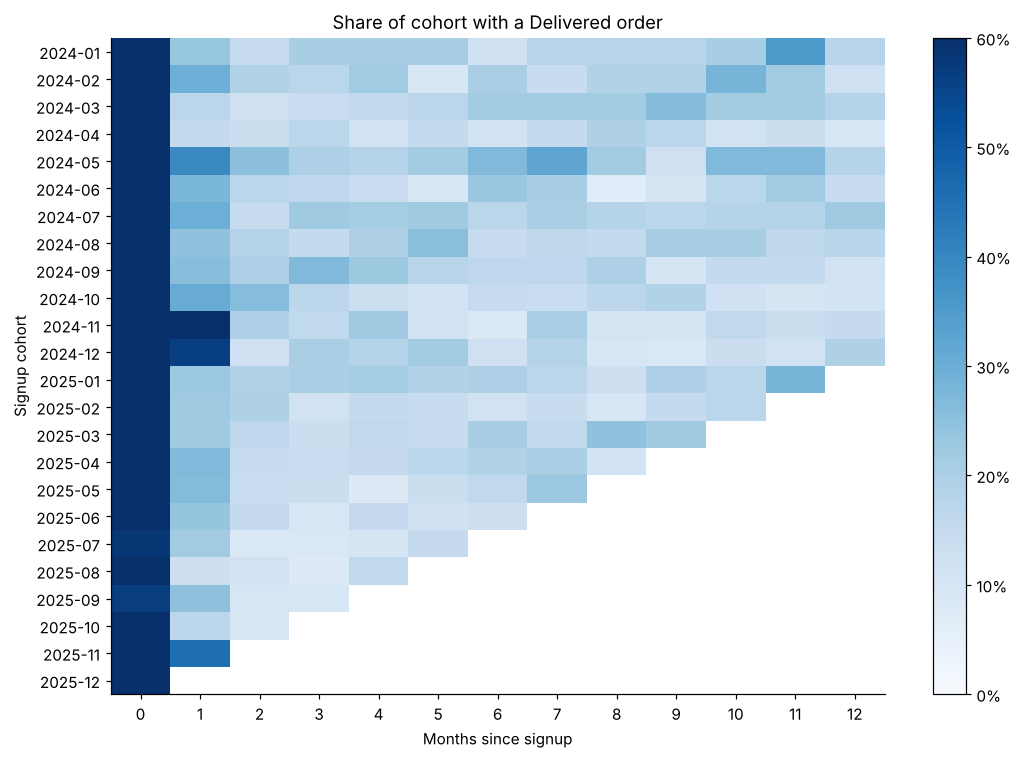

In [12]:
d = delivered[["customer_id", "order_date"]].drop_duplicates().merge(cust[["customer_id", "signup_date"]], on="customer_id")
d["cohort"] = d.signup_date.dt.to_period("M")
d["period"] = (d.order_date.dt.to_period("M") - d.cohort).apply(lambda x: x.n)

cohort_size = cust.groupby(cust.signup_date.dt.to_period("M")).customer_id.nunique()
active = d.groupby(["cohort", "period"]).customer_id.nunique().unstack(fill_value=0)
retention = active.div(cohort_size, axis=0).loc[:, 0:12]
# blank out months that haven't happened yet (data ends Dec 2025)
months_observed = np.array([(pd.Period("2025-12", "M") - c).n for c in retention.index])
retention = retention.where(np.arange(retention.shape[1])[None, :] <= months_observed[:, None])

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(retention.values, cmap="Blues", aspect="auto", vmin=0, vmax=0.6)
ax.set_xticks(range(retention.shape[1])); ax.set_xticklabels(retention.columns)
ax.set_yticks(range(len(retention))); ax.set_yticklabels(retention.index.astype(str))
ax.set_xlabel("Months since signup"); ax.set_ylabel("Signup cohort"); ax.set_title("Share of cohort with a Delivered order")
fig.colorbar(im, ax=ax, format=lambda x, _: f"{x:.0%}")
plt.tight_layout(); plt.show()

orders_per_cust = delivered.groupby("customer_id").order_id.nunique()
print("Customers with ≥1 delivered order:", len(orders_per_cust))
print("…of whom repeat (≥2): {:.0%}".format((orders_per_cust >= 2).mean()))
print("Signed up but never had a delivered order: {:.0%}".format(1 - len(orders_per_cust) / len(cust)))
print("\nAverage month-1 to month-6 retention: {:.1%}".format(retention.loc[:, 1:6].stack().mean()))

**Takeaway:** About 6 in 10 buyers order again, but only ~18% of a cohort is active in any given later month. Customers buy every few months, not monthly, which makes a beans subscription a natural fit. About 1 in 8 signups never completes a delivered order, a cheap win for an onboarding email.

### 3.4 Acquisition channels

                     customers  buyer_rate  repeat_rate  rev_180d_per_customer
acquisition_channel                                                           
Referral                   206        0.96         0.79                 178.77
Email                      263        0.93         0.70                 153.63
Unknown                     40        0.98         0.82                 150.69
Organic Search             519        0.91         0.63                 121.10
Paid Search                280        0.93         0.59                 112.18
Paid Social                400        0.89         0.50                  97.57


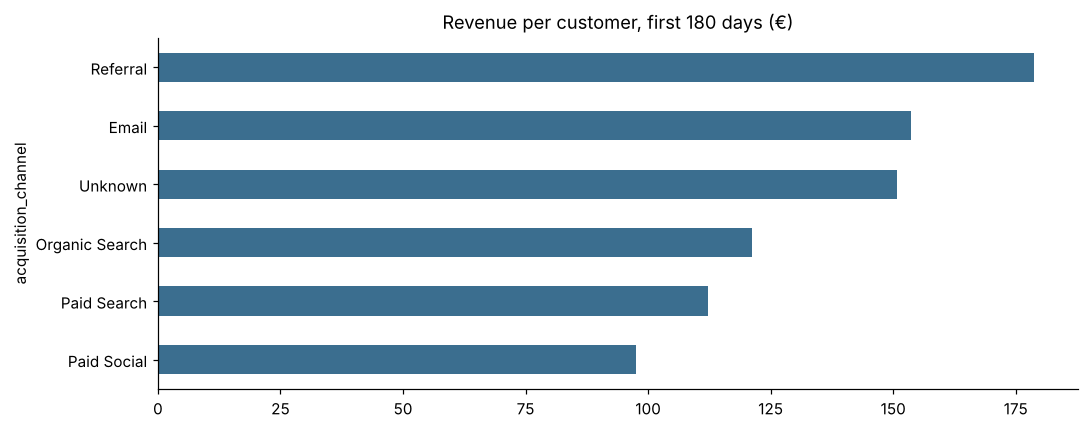

In [13]:
first_order = delivered.groupby("customer_id").order_date.min().rename("first_order")
cl = delivered.merge(first_order, on="customer_id")
rev180 = cl[cl.order_date <= cl.first_order + pd.Timedelta(days=180)].groupby("customer_id").revenue.sum().rename("rev_180d")

ch = cust.set_index("customer_id")[["acquisition_channel", "signup_date"]].join(orders_per_cust.rename("n_orders")).join(rev180)
ch["n_orders"] = ch.n_orders.fillna(0)
# only customers who had a full 180 days to buy
mature = ch[ch.signup_date <= "2025-06-30"]
summary = mature.groupby("acquisition_channel").agg(
    customers=("n_orders", "size"),
    buyer_rate=("n_orders", lambda s: (s >= 1).mean()),
    repeat_rate=("n_orders", lambda s: (s >= 2).mean()),
    rev_180d_per_customer=("rev_180d", lambda s: s.fillna(0).mean()),
).sort_values("rev_180d_per_customer", ascending=False)
print(summary.round(2))

summary.rev_180d_per_customer.plot.barh(color="#3b6e8f", title="Revenue per customer, first 180 days (€)", xlabel="")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

**Takeaway:** Referral and Email customers are worth roughly 1.6–1.8× a Paid Social customer in their first six months (€179 / €154 vs €98), and they repeat far more often. Paid Social brings volume but low-value customers. To decide whether it's *worth it*, we need **spend per channel** to compute CAC and compare it with this 180-day value. A good next ask for Eleni.

*Why only customers who signed up by June 2025?* Later signups haven't had 180 days to buy yet; including them would unfairly penalise channels that grew recently.

### 3.5 RFM segmentation

In [14]:
snapshot = pd.Timestamp("2025-12-31")
rfm = delivered.groupby("customer_id").agg(
    recency=("order_date", lambda s: (snapshot - s.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("revenue", "sum"))

score = lambda s, asc: pd.qcut(s.rank(method="first", ascending=asc), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["R"] = score(rfm.recency, False)      # recent = high score
rfm["F"] = score(rfm.frequency, True)
rfm["M"] = score(rfm.monetary, True)

def segment(r):
    if r.R >= 4 and r.F >= 4: return "Champions"
    if r.R >= 3 and r.F >= 3: return "Loyal"
    if r.R >= 4 and r.F <= 2: return "New / Promising"
    if r.R <= 2 and r.F >= 3: return "At Risk"
    return "Hibernating / Lost"
rfm["segment"] = rfm.apply(segment, axis=1)

seg = rfm.groupby("segment").agg(customers=("monetary", "size"), revenue=("monetary", "sum"),
                                 avg_recency_days=("recency", "mean"), avg_orders=("frequency", "mean"))
seg["pct_customers"] = seg.customers / seg.customers.sum()
seg["pct_revenue"] = seg.revenue / seg.revenue.sum()
print(seg.sort_values("revenue", ascending=False).round(2))

                    customers    revenue  avg_recency_days  avg_orders  \
segment                                                                  
Champions                 552  244529.31             22.96        8.49   
Loyal                     440   87478.78             70.02        3.68   
At Risk                   317   57507.32            289.72        3.31   
Hibernating / Lost        750   44057.31            283.92        1.01   
New / Promising           123    6631.58             35.97        1.11   

                    pct_customers  pct_revenue  
segment                                         
Champions                    0.25         0.56  
Loyal                        0.20         0.20  
At Risk                      0.15         0.13  
Hibernating / Lost           0.34         0.10  
New / Promising              0.06         0.02  


**Takeaway:** Champions + Loyal are ~45% of buyers but ~75% of revenue. The At Risk segment, made up of formerly frequent buyers who haven't ordered recently, is the most valuable group to win back with a targeted email offer.

### 3.6 Cancellations & returns

In [15]:
o = ords.merge(cust[["customer_id", "country"]], on="customer_id")
o["bad"] = o.status.isin(["Cancelled", "Returned"])
for col in ["payment_method", "country"]:
    print(o.groupby(col).agg(orders=("bad", "size"), cancel_or_return_rate=("bad", "mean")).sort_values("cancel_or_return_rate", ascending=False).round(3), "\n")

ol = order_lines.copy(); ol["bad"] = ol.status.isin(["Cancelled", "Returned"])
print(ol.groupby("category").bad.mean().round(3))

                orders  cancel_or_return_rate
payment_method                               
Bank Transfer      793                  0.187
PayPal            3179                  0.171
Card              5999                  0.171 

             orders  cancel_or_return_rate
country                                   
Netherlands     524                  0.195
Spain           550                  0.193
Italy          1055                  0.184
France          858                  0.183
Greece         4486                  0.169
Germany        1399                  0.161
Cyprus          634                  0.158
Austria         465                  0.153 

category
Accessories     0.173
Coffee Beans    0.174
Equipment       0.175
Tea             0.176
Name: bad, dtype: float64


**Takeaway:** Cancellation and return rates (~17% combined) are flat across countries, payment methods and categories; no single segment is the culprit. Honest answer: nothing stands out, and that is a valid finding. Reason codes on cancellations and returns would be the data to collect next.

---
## Summary & recommendations

**Key findings**
1. **Strong growth, very seasonal.** Net revenue grew ~160% from 2024 to 2025 (€122k → €319k), almost entirely from more customers. November and December alone bring ~28% of the year's revenue.
2. **Coffee beans are the engine.** Beans combine volume, healthy margins (~56%) and repeat purchases. Discounted gift cards are sold at a loss.
3. **Customers come back, but slowly.** About 6 in 10 buyers order again, usually months later. One in eight signups never completes an order.
4. **Paid Social brings the cheapest-quality customers.** Their 6-month value is about half a Referral customer's (€98 vs €179), and only 50% repeat vs 79%.
5. **The data needs some hygiene.** Duplicate records, test orders and inconsistent formats would have overstated revenue if left in.

**Recommendations**
1. Launch a **beans subscription** (e.g. every 4–6 weeks) to turn slow repeaters into predictable revenue.
2. **Grow referrals:** a give-€5/get-€5 scheme, funded by shifting part of the Paid Social budget, *once we confirm channel costs*.
3. **Plan for Q4 from September:** stock equipment and gift bundles early, send a win-back email to the ~320 At Risk customers before November, and stop discounting gift cards.

**Caveats & data we'd need**
- No marketing spend by channel, so we can't compute customer acquisition cost or ROI.
- No reason codes for cancellations and returns.
- Gift-card sales are counted as revenue here; finance may want them treated as a liability until redeemed.